# Milestone 3: Evaluation, Parameter Sensitivity & Fine-Tuning Comparison

**Continues from:** Milestone 2 (`milestone2_output/best_model.pt`, Milestone 1 artifacts)

**Tasks covered:**
1. Compute quantitative metrics: BLEU-1/4, METEOR, CIDEr, ROUGE-L on the full validation set across all decoding strategies.
2. Analyze parameter sensitivity (temperature, beam width, embedding injection method) and compare fine-tuning strategies (full fine-tuning vs. LoRA vs. prefix tuning).
3. Visualize & compare results across decoding strategies.
4. Evaluate robustness on VizWiz-Captions (accessibility dataset).

**Outputs:** Evaluation tables, parameter sweep plots, fine-tuning comparison, VizWiz analysis.

## 1. Environment Setup

In [1]:
%pip install -q torch torchvision transformers datasets pillow matplotlib pandas requests pycocoevalcap peft rouge-score nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, time, math, random, re, datetime, textwrap, warnings
from collections import Counter, defaultdict
from io import BytesIO

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import requests
from PIL import Image
from transformers import GPT2Tokenizer, GPT2LMHeadModel, CLIPModel, CLIPProcessor

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('wordnet', quiet=True)

from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.meteor.meteor import Meteor
from rouge_score import rouge_scorer

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

# === PATHS — update these for your setup ===
M1_DIR = "/kaggle/input/notebooks/reshmasrig/milestone-1/milestone1_output"
M2_DIR = "/kaggle/input/notebooks/reshmasrig/milestone-2/milestone2_output"
OUT_DIR = "milestone3_output"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUT_DIR, "plots"), exist_ok=True)

Device: cuda


## 2. Load Artifacts from Milestone 1 & 2

In [3]:
def safe_torch_load(path):
    try:
        return torch.load(path, map_location="cpu")
    except Exception:
        return torch.load(path, map_location="cpu", weights_only=False)

# M1 artifacts
clip_embeddings = safe_torch_load(os.path.join(M1_DIR, "clip_embeddings.pt")).float()
tok_data = safe_torch_load(os.path.join(M1_DIR, "tokenized_captions.pt"))
with open(os.path.join(M1_DIR, "metadata.json")) as f:
    metadata = json.load(f)

raw_captions = list(tok_data["raw_captions"])
caption_to_image = [int(i) for i in tok_data["caption_to_image"]]
NUM_IMAGES, CLIP_DIM = clip_embeddings.shape

image_to_captions = {}
for ci, img in enumerate(caption_to_image):
    image_to_captions.setdefault(img, []).append(raw_captions[ci])

print(f"Loaded {NUM_IMAGES} CLIP embeddings (dim {CLIP_DIM}), {len(raw_captions)} captions")

Loaded 5000 CLIP embeddings (dim 512), 25013 captions


In [4]:
# Reproduce train/val split (same as M2)
all_image_ids = sorted(image_to_captions.keys())
random.seed(SEED)
random.shuffle(all_image_ids)
val_fraction = 0.10
n_val = int(len(all_image_ids) * val_fraction)
val_image_ids = set(all_image_ids[:n_val])
train_image_ids = set(all_image_ids[n_val:])
print(f"Train: {len(train_image_ids)} images, Val: {len(val_image_ids)} images")

Train: 4500 images, Val: 500 images


## 3. Rebuild Model Architecture & Load M2 Checkpoint

In [5]:
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token
EOS_ID = tokenizer.eos_token_id
GPT2_DIM = 768
PREFIX_LENGTH = 10


class MLPMapper(nn.Module):
    def __init__(self, clip_dim=512, gpt2_dim=768, prefix_length=10):
        super().__init__()
        hidden = prefix_length * gpt2_dim // 2
        out_dim = prefix_length * gpt2_dim
        self.net = nn.Sequential(
            nn.Linear(clip_dim, hidden), nn.GELU(),
            nn.Linear(hidden, out_dim),
        )
        self.prefix_length = prefix_length
        self.gpt2_dim = gpt2_dim

    def forward(self, clip_emb):
        return self.net(clip_emb).view(-1, self.prefix_length, self.gpt2_dim)


class CaptionModel(nn.Module):
    def __init__(self, clip_dim=512, gpt2_dim=768, prefix_length=10):
        super().__init__()
        self.gpt2 = GPT2LMHeadModel.from_pretrained("gpt2")
        self.gpt2.resize_token_embeddings(len(tokenizer))
        self.mapper = MLPMapper(clip_dim, gpt2_dim, prefix_length)
        self.prefix_length = prefix_length

    def forward(self, clip_emb, input_ids, attention_mask):
        prefix = self.mapper(clip_emb)
        token_emb = self.gpt2.transformer.wte(input_ids)
        inputs_embeds = torch.cat([prefix, token_emb], dim=1)
        prefix_mask = torch.ones(prefix.shape[0], prefix.shape[1], device=prefix.device)
        full_mask = torch.cat([prefix_mask, attention_mask], dim=1)
        out = self.gpt2(inputs_embeds=inputs_embeds, attention_mask=full_mask)
        return out.logits[:, self.prefix_length:, :]


def fix_checkpoint_keys(state_dict):
    fixed = {}
    for k, v in state_dict.items():
        new_key = k.replace("gpt.", "gpt2.") if k.startswith("gpt.") else k
        fixed[new_key] = v
    return fixed


model = CaptionModel(CLIP_DIM, GPT2_DIM, PREFIX_LENGTH).to(DEVICE)
ckpt = safe_torch_load(os.path.join(M2_DIR, "best_model.pt"))
fixed_state_dict = fix_checkpoint_keys(ckpt["model"])
model.load_state_dict(fixed_state_dict)
model.eval()
print(f"Loaded M2 best checkpoint (epoch {ckpt.get('epoch', '?')})")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Loaded M2 best checkpoint (epoch 4)


## 4. Decoding Functions

In [6]:
def ids_to_text(ids):
    if EOS_ID in ids:
        ids = ids[:ids.index(EOS_ID)]
    return tokenizer.decode(ids, skip_special_tokens=True).strip()


@torch.no_grad()
def generate_greedy(model, clip_emb, max_tokens=30):
    prefix = model.mapper(clip_emb.unsqueeze(0).to(DEVICE))
    generated = []
    past = None
    inputs_embeds = prefix
    for _ in range(max_tokens):
        out = model.gpt2(inputs_embeds=inputs_embeds, past_key_values=past, use_cache=True)
        logits = out.logits[:, -1, :]
        token = logits.argmax(-1).item()
        if token == EOS_ID:
            break
        generated.append(token)
        past = out.past_key_values
        inputs_embeds = model.gpt2.transformer.wte(torch.tensor([[token]], device=DEVICE))
    return ids_to_text(generated)


@torch.no_grad()
def generate_beam(model, clip_emb, beam_k=5, max_tokens=30):
    prefix = model.mapper(clip_emb.unsqueeze(0).to(DEVICE))
    beams = [([], 0.0, prefix, None)]
    for _ in range(max_tokens):
        candidates = []
        for seq, score, emb, past in beams:
            if seq and seq[-1] == EOS_ID:
                candidates.append((seq, score, emb, past))
                continue
            out = model.gpt2(inputs_embeds=emb, past_key_values=past, use_cache=True)
            logits = out.logits[:, -1, :]
            log_probs = F.log_softmax(logits, dim=-1)
            topk = log_probs.topk(beam_k, dim=-1)
            for i in range(beam_k):
                tok = topk.indices[0, i].item()
                new_score = score + topk.values[0, i].item()
                new_emb = model.gpt2.transformer.wte(torch.tensor([[tok]], device=DEVICE))
                candidates.append((seq + [tok], new_score, new_emb, out.past_key_values))
        beams = sorted(candidates, key=lambda x: x[1] / max(len(x[0]), 1), reverse=True)[:beam_k]
        if all(b[0] and b[0][-1] == EOS_ID for b in beams):
            break
    return ids_to_text(beams[0][0])


@torch.no_grad()
def generate_nucleus(model, clip_emb, p=0.9, temperature=0.7, max_tokens=30):
    prefix = model.mapper(clip_emb.unsqueeze(0).to(DEVICE))
    generated = []
    past = None
    inputs_embeds = prefix
    for _ in range(max_tokens):
        out = model.gpt2(inputs_embeds=inputs_embeds, past_key_values=past, use_cache=True)
        logits = out.logits[:, -1, :] / temperature
        sorted_logits, sorted_idx = torch.sort(logits, descending=True)
        cum_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
        cutoff = (cum_probs - F.softmax(sorted_logits, dim=-1)) >= p
        sorted_logits[cutoff] = -float('inf')
        probs = F.softmax(sorted_logits, dim=-1)
        token = sorted_idx[0, torch.multinomial(probs, 1).item()].item()
        if token == EOS_ID:
            break
        generated.append(token)
        past = out.past_key_values
        inputs_embeds = model.gpt2.transformer.wte(torch.tensor([[token]], device=DEVICE))
    return ids_to_text(generated)

## 5. Quantitative Evaluation on Full Validation Set

In [7]:
from nltk.translate.meteor_score import meteor_score as nltk_meteor

def compute_metrics(hypotheses, references_dict):
    """Compute BLEU-1/4, METEOR, CIDEr, ROUGE-L.
    hypotheses: {img_id: [caption_string]}
    references_dict: {img_id: [list of reference strings]}
    """
    gts = {k: v for k, v in references_dict.items()}
    res = {k: v for k, v in hypotheses.items()}

    bleu_scorer = Bleu(4)
    bleu_scores, _ = bleu_scorer.compute_score(gts, res)

    cider_scorer = Cider()
    cider_score, _ = cider_scorer.compute_score(gts, res)

    # METEOR using nltk (no Java needed)
    meteor_scores = []
    for img_id in gts:
        hyp = res[img_id][0].split()
        ref_list = [r.split() for r in gts[img_id]]
        meteor_scores.append(nltk_meteor(ref_list, hyp))
    meteor_score = np.mean(meteor_scores)

    # ROUGE-L
    scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)
    rouge_scores = []
    for img_id in gts:
        hyp = res[img_id][0]
        refs = gts[img_id]
        best = max(scorer.score(ref, hyp)['rougeL'].fmeasure for ref in refs)
        rouge_scores.append(best)
    rouge_l = np.mean(rouge_scores)

    return {
        "BLEU-1": bleu_scores[0],
        "BLEU-2": bleu_scores[1],
        "BLEU-3": bleu_scores[2],
        "BLEU-4": bleu_scores[3],
        "METEOR": meteor_score,
        "CIDEr": cider_score,
        "ROUGE-L": rouge_l,
    }

print("Metric computation functions ready.")

Metric computation functions ready.


In [8]:
# Generate captions for full validation set with each strategy
EVAL_IDS = sorted(val_image_ids)
print(f"Evaluating on {len(EVAL_IDS)} validation images...\n")

# Build reference dict
refs = {img_id: image_to_captions[img_id] for img_id in EVAL_IDS}

strategies = {
    "Greedy": lambda emb: generate_greedy(model, emb),
    "Beam (k=3)": lambda emb: generate_beam(model, emb, beam_k=3),
    "Beam (k=5)": lambda emb: generate_beam(model, emb, beam_k=5),
    "Nucleus (p=0.9, T=0.7)": lambda emb: generate_nucleus(model, emb, p=0.9, temperature=0.7),
    "Nucleus (p=0.9, T=1.0)": lambda emb: generate_nucleus(model, emb, p=0.9, temperature=1.0),
}

all_results = {}
for name, gen_fn in strategies.items():
    print(f"Running {name}...")
    hyps = {}
    t0 = time.time()
    for img_id in EVAL_IDS:
        caption = gen_fn(clip_embeddings[img_id])
        hyps[img_id] = [caption]
    elapsed = time.time() - t0

    metrics = compute_metrics(hyps, refs)
    metrics["Time (s)"] = round(elapsed, 1)
    all_results[name] = metrics
    print(f"  BLEU-4: {metrics['BLEU-4']:.4f} | CIDEr: {metrics['CIDEr']:.4f} | "
          f"METEOR: {metrics['METEOR']:.4f} | ROUGE-L: {metrics['ROUGE-L']:.4f} | {elapsed:.1f}s")

print("\nDone.")

Evaluating on 500 validation images...

Running Greedy...
{'testlen': 4607, 'reflen': 4664, 'guess': [4607, 4107, 3607, 3107], 'correct': [3499, 1957, 936, 446]}
ratio: 0.9877787307030471
  BLEU-4: 0.3366 | CIDEr: 1.1515 | METEOR: 0.4991 | ROUGE-L: 0.5655 | 47.6s
Running Beam (k=3)...
{'testlen': 2915, 'reflen': 4306, 'guess': [2915, 2415, 1915, 1416], 'correct': [2176, 1036, 348, 94]}
ratio: 0.6769623780769445
  BLEU-4: 0.1547 | CIDEr: 0.6870 | METEOR: 0.3425 | ROUGE-L: 0.4837 | 89.1s
Running Beam (k=5)...
{'testlen': 3012, 'reflen': 4421, 'guess': [3012, 2512, 2012, 1540], 'correct': [1819, 828, 271, 64]}
ratio: 0.6812938249263331
  BLEU-4: 0.1144 | CIDEr: 0.5191 | METEOR: 0.2852 | ROUGE-L: 0.4382 | 168.1s
Running Nucleus (p=0.9, T=0.7)...
{'testlen': 4872, 'reflen': 4866, 'guess': [4872, 4372, 3872, 3372], 'correct': [3395, 1704, 747, 312]}
ratio: 1.0012330456224823
  BLEU-4: 0.2639 | CIDEr: 0.9920 | METEOR: 0.4674 | ROUGE-L: 0.5223 | 53.9s
Running Nucleus (p=0.9, T=1.0)...
{'testle

In [9]:
# Results table
results_df = pd.DataFrame(all_results).T
results_df.index.name = "Strategy"
results_df = results_df[["BLEU-1", "BLEU-4", "METEOR", "CIDEr", "ROUGE-L", "Time (s)"]]
results_df = results_df.round(4)
results_df.to_csv(os.path.join(OUT_DIR, "decoding_metrics.csv"))
print("\nTable 1: Quantitative Metrics by Decoding Strategy")
print("=" * 80)
print(results_df.to_string())


Table 1: Quantitative Metrics by Decoding Strategy
                        BLEU-1  BLEU-4  METEOR   CIDEr  ROUGE-L  Time (s)
Strategy                                                                 
Greedy                  0.7502  0.3366  0.4991  1.1515   0.5655      47.6
Beam (k=3)              0.4632  0.1547  0.3425  0.6870   0.4837      89.1
Beam (k=5)              0.3783  0.1144  0.2852  0.5191   0.4382     168.1
Nucleus (p=0.9, T=0.7)  0.6968  0.2639  0.4674  0.9920   0.5223      53.9
Nucleus (p=0.9, T=1.0)  0.6096  0.1763  0.3979  0.7050   0.4508      53.3


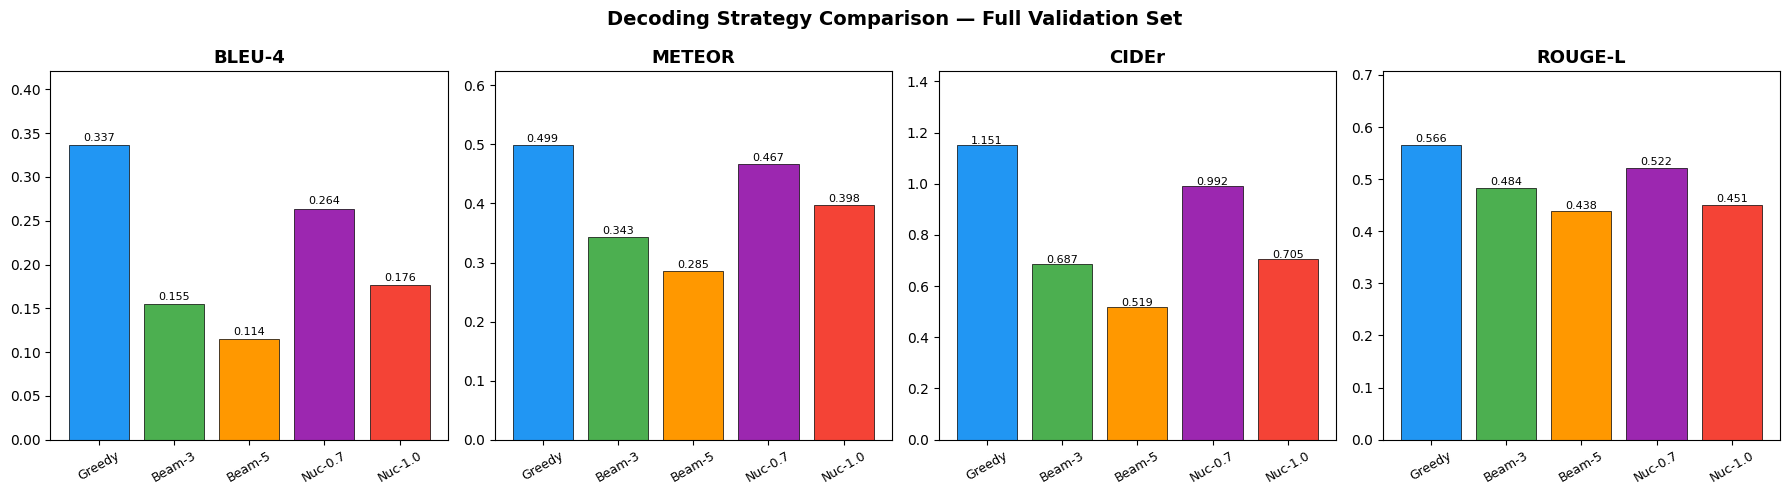

In [10]:
# Bar chart comparing metrics across strategies
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
metrics_to_plot = ["BLEU-4", "METEOR", "CIDEr", "ROUGE-L"]
colors = ["#2196F3", "#4CAF50", "#FF9800", "#9C27B0", "#F44336"]
strategy_names = list(all_results.keys())
short_names = ["Greedy", "Beam-3", "Beam-5", "Nuc-0.7", "Nuc-1.0"]

for ax, metric in zip(axes, metrics_to_plot):
    values = [all_results[s][metric] for s in strategy_names]
    bars = ax.bar(short_names, values, color=colors, edgecolor='black', linewidth=0.5)
    ax.set_title(metric, fontsize=13, fontweight='bold')
    ax.set_ylim(0, max(values) * 1.25)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f"{val:.3f}", ha='center', fontsize=8)
    ax.tick_params(axis='x', rotation=30, labelsize=9)

fig.suptitle("Decoding Strategy Comparison — Full Validation Set", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "plots", "decoding_comparison.png"), dpi=150, bbox_inches='tight')
plt.show()

## 6. Parameter Sensitivity Analysis

In [11]:
# 6a. Temperature sweep (nucleus sampling, p=0.9)
temperatures = [0.3, 0.5, 0.7, 0.9, 1.0, 1.2]
temp_results = {}

print("Temperature sweep (nucleus p=0.9)...")
for temp in temperatures:
    hyps = {}
    for img_id in EVAL_IDS:
        hyps[img_id] = [generate_nucleus(model, clip_embeddings[img_id], p=0.9, temperature=temp)]
    metrics = compute_metrics(hyps, refs)
    temp_results[temp] = metrics
    print(f"  T={temp:.1f}: BLEU-4={metrics['BLEU-4']:.4f} CIDEr={metrics['CIDEr']:.4f} METEOR={metrics['METEOR']:.4f}")

print("Done.")

Temperature sweep (nucleus p=0.9)...
{'testlen': 4659, 'reflen': 4707, 'guess': [4659, 4159, 3659, 3159], 'correct': [3477, 1900, 885, 411]}
ratio: 0.9898024219245825
  T=0.3: BLEU-4=0.3185 CIDEr=1.1361 METEOR=0.4962
{'testlen': 4698, 'reflen': 4714, 'guess': [4698, 4198, 3698, 3198], 'correct': [3440, 1827, 818, 372]}
ratio: 0.9966058549000855
  T=0.5: BLEU-4=0.2999 CIDEr=1.0564 METEOR=0.4832
{'testlen': 4919, 'reflen': 4879, 'guess': [4919, 4419, 3919, 3419], 'correct': [3361, 1653, 703, 315]}
ratio: 1.0081984013115375
  T=0.7: BLEU-4=0.2549 CIDEr=0.9376 METEOR=0.4647
{'testlen': 4909, 'reflen': 4884, 'guess': [4909, 4409, 3909, 3409], 'correct': [3136, 1414, 547, 219]}
ratio: 1.0051187551185492
  T=0.9: BLEU-4=0.2072 CIDEr=0.8003 METEOR=0.4201
{'testlen': 4956, 'reflen': 4896, 'guess': [4956, 4456, 3956, 3456], 'correct': [3012, 1229, 446, 154]}
ratio: 1.0122549019605775
  T=1.0: BLEU-4=0.1703 CIDEr=0.7319 METEOR=0.4018
{'testlen': 5170, 'reflen': 5028, 'guess': [5170, 4670, 4170, 3

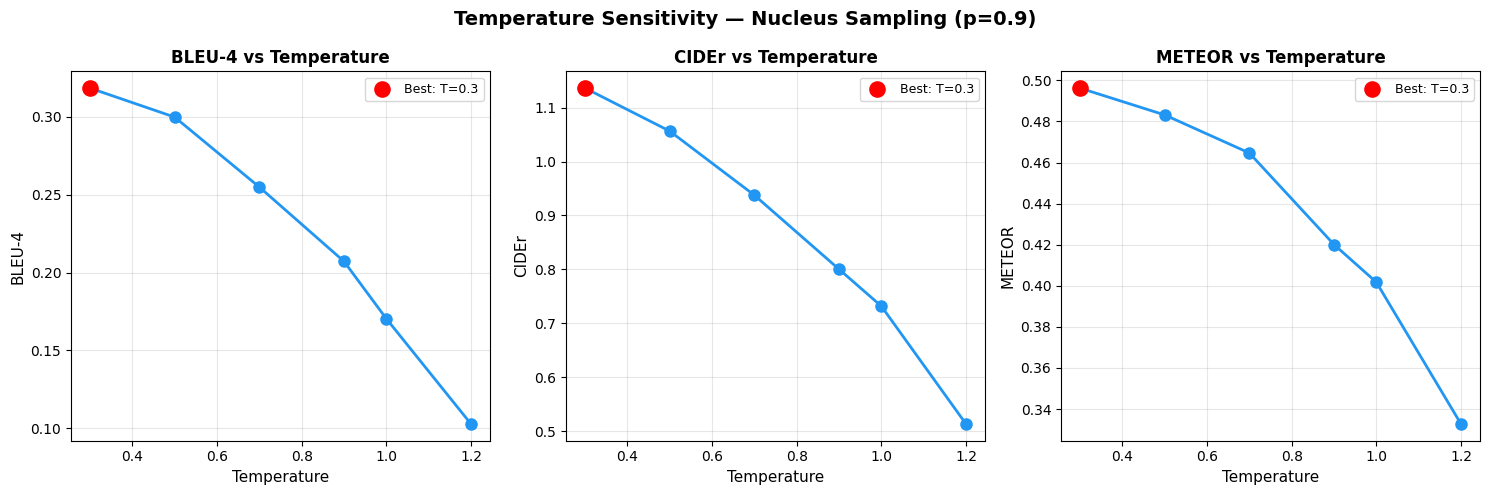

             BLEU-1  BLEU-4  METEOR   CIDEr  ROUGE-L
Temperature                                         
0.3          0.7386  0.3185  0.4962  1.1361   0.5574
0.5          0.7297  0.2999  0.4832  1.0564   0.5405
0.7          0.6833  0.2549  0.4647  0.9376   0.5216
0.9          0.6388  0.2072  0.4201  0.8003   0.4761
1.0          0.6077  0.1703  0.4018  0.7319   0.4547
1.2          0.5110  0.1027  0.3328  0.5135   0.3837


In [12]:
# Temperature sweep plot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
temps = list(temp_results.keys())

for ax, metric in zip(axes, ["BLEU-4", "CIDEr", "METEOR"]):
    values = [temp_results[t][metric] for t in temps]
    ax.plot(temps, values, 'o-', color='#2196F3', linewidth=2, markersize=8)
    ax.set_xlabel("Temperature", fontsize=11)
    ax.set_ylabel(metric, fontsize=11)
    ax.set_title(f"{metric} vs Temperature", fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    best_idx = np.argmax(values)
    ax.scatter(temps[best_idx], values[best_idx], color='red', s=120, zorder=5, label=f'Best: T={temps[best_idx]}')
    ax.legend(fontsize=9)

fig.suptitle("Temperature Sensitivity — Nucleus Sampling (p=0.9)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "plots", "temperature_sweep.png"), dpi=150, bbox_inches='tight')
plt.show()

temp_df = pd.DataFrame(temp_results).T
temp_df.index.name = "Temperature"
temp_df = temp_df[["BLEU-1", "BLEU-4", "METEOR", "CIDEr", "ROUGE-L"]].round(4)
temp_df.to_csv(os.path.join(OUT_DIR, "temperature_sweep.csv"))
print(temp_df.to_string())

In [13]:
# 6b. Beam width sweep
beam_widths = [1, 2, 3, 5, 7, 10]
beam_results = {}

print("Beam width sweep...")
for k in beam_widths:
    hyps = {}
    t0 = time.time()
    for img_id in EVAL_IDS:
        if k == 1:
            hyps[img_id] = [generate_greedy(model, clip_embeddings[img_id])]
        else:
            hyps[img_id] = [generate_beam(model, clip_embeddings[img_id], beam_k=k)]
    elapsed = time.time() - t0
    metrics = compute_metrics(hyps, refs)
    metrics["Time (s)"] = round(elapsed, 1)
    beam_results[k] = metrics
    print(f"  k={k}: BLEU-4={metrics['BLEU-4']:.4f} CIDEr={metrics['CIDEr']:.4f} Time={elapsed:.1f}s")

print("Done.")

Beam width sweep...
{'testlen': 4607, 'reflen': 4664, 'guess': [4607, 4107, 3607, 3107], 'correct': [3499, 1957, 936, 446]}
ratio: 0.9877787307030471
  k=1: BLEU-4=0.3366 CIDEr=1.1515 Time=46.0s
{'testlen': 3349, 'reflen': 4314, 'guess': [3349, 2849, 2349, 1849], 'correct': [2558, 1259, 467, 151]}
ratio: 0.7763096893832229
  k=2: BLEU-4=0.2040 CIDEr=0.8282 Time=67.1s
{'testlen': 2915, 'reflen': 4306, 'guess': [2915, 2415, 1915, 1416], 'correct': [2176, 1036, 348, 94]}
ratio: 0.6769623780769445
  k=3: BLEU-4=0.1547 CIDEr=0.6870 Time=89.0s
{'testlen': 3012, 'reflen': 4421, 'guess': [3012, 2512, 2012, 1540], 'correct': [1819, 828, 271, 64]}
ratio: 0.6812938249263331
  k=5: BLEU-4=0.1144 CIDEr=0.5191 Time=164.2s
{'testlen': 3714, 'reflen': 4637, 'guess': [3714, 3214, 2715, 2270], 'correct': [1783, 752, 227, 50]}
ratio: 0.8009488893679532
  k=7: BLEU-4=0.0935 CIDEr=0.4325 Time=311.8s
{'testlen': 6027, 'reflen': 5085, 'guess': [6027, 5527, 5029, 4634], 'correct': [1896, 720, 182, 37]}
ratio:

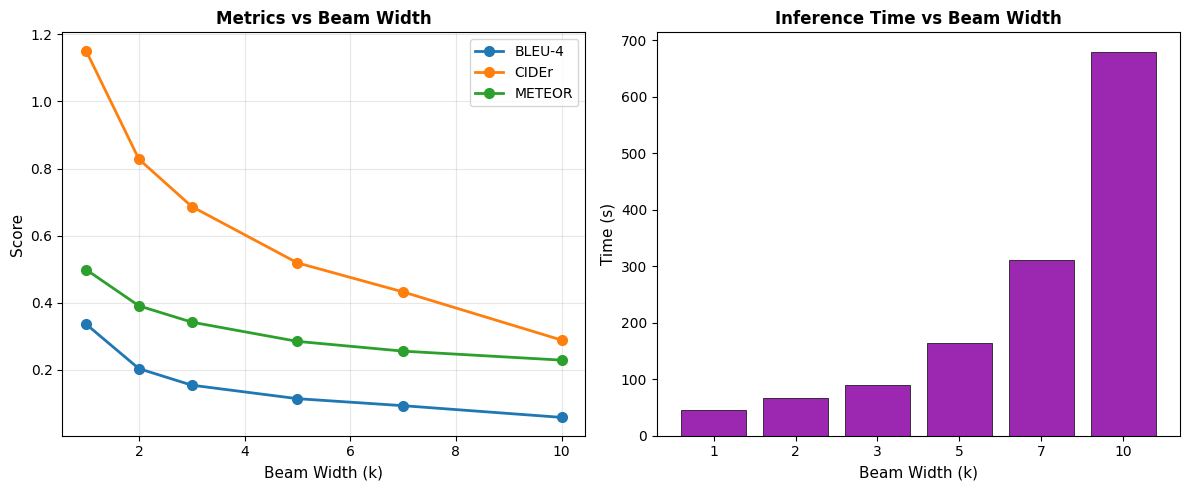

            BLEU-1  BLEU-4  METEOR   CIDEr  ROUGE-L  Time (s)
Beam Width                                                   
1           0.7502  0.3366  0.4991  1.1515   0.5655      46.0
2           0.5726  0.2040  0.3911  0.8282   0.5139      67.1
3           0.4632  0.1547  0.3425  0.6870   0.4837      89.0
5           0.3783  0.1144  0.2852  0.5191   0.4382     164.2
7           0.3744  0.0935  0.2561  0.4325   0.3984     311.8
10          0.3146  0.0587  0.2293  0.2891   0.3382     680.4


In [14]:
# Beam width plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ks = list(beam_results.keys())

for metric, color in [("BLEU-4", "#2196F3"), ("CIDEr", "#4CAF50"), ("METEOR", "#FF9800")]:
    vals = [beam_results[k][metric] for k in ks]
    ax1.plot(ks, vals, 'o-', label=metric, linewidth=2, markersize=7)
ax1.set_xlabel("Beam Width (k)", fontsize=11)
ax1.set_ylabel("Score", fontsize=11)
ax1.set_title("Metrics vs Beam Width", fontsize=12, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

times = [beam_results[k]["Time (s)"] for k in ks]
ax2.bar([str(k) for k in ks], times, color='#9C27B0', edgecolor='black', linewidth=0.5)
ax2.set_xlabel("Beam Width (k)", fontsize=11)
ax2.set_ylabel("Time (s)", fontsize=11)
ax2.set_title("Inference Time vs Beam Width", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "plots", "beam_width_sweep.png"), dpi=150, bbox_inches='tight')
plt.show()

beam_df = pd.DataFrame(beam_results).T
beam_df.index.name = "Beam Width"
beam_df = beam_df[["BLEU-1", "BLEU-4", "METEOR", "CIDEr", "ROUGE-L", "Time (s)"]].round(4)
beam_df.to_csv(os.path.join(OUT_DIR, "beam_width_sweep.csv"))
print(beam_df.to_string())

## 7. Fine-Tuning Strategy Comparison

Compare three strategies:
1. **Full fine-tuning** (M2 model): mapper + all GPT-2 parameters trained
2. **LoRA**: mapper + low-rank adapters on GPT-2 attention layers (GPT-2 base frozen)
3. **Prefix tuning only**: mapper trained, GPT-2 entirely frozen

In [15]:
# Dataset class (same as M2)
class CaptionDataset(Dataset):
    def __init__(self, image_ids, image_to_captions, clip_embeddings, tokenizer, max_len=40):
        self.samples = []
        for img_id in image_ids:
            emb = clip_embeddings[img_id]
            for cap in image_to_captions[img_id]:
                tok = tokenizer(cap, max_length=max_len, padding="max_length",
                                truncation=True, return_tensors="pt")
                self.samples.append((emb, tok["input_ids"].squeeze(), tok["attention_mask"].squeeze()))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]


train_ds = CaptionDataset(sorted(train_image_ids), image_to_captions, clip_embeddings, tokenizer)
val_ds = CaptionDataset(sorted(val_image_ids), image_to_captions, clip_embeddings, tokenizer)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
print(f"Train: {len(train_ds)} samples, Val: {len(val_ds)} samples")

Train: 22511 samples, Val: 2502 samples


In [16]:
def train_model(model, train_loader, val_loader, epochs=3, lr=2e-4, strategy_name=""):
    """Quick training loop for comparison. Returns best val loss and training history."""
    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=0.01)
    best_val = float('inf')
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, n_batches = 0, 0
        for emb, ids, mask in train_loader:
            emb, ids, mask = emb.to(DEVICE), ids.to(DEVICE), mask.to(DEVICE)
            logits = model(emb, ids, mask)
            shift_logits = logits[:, :-1, :].contiguous()
            shift_labels = ids[:, 1:].contiguous()
            shift_mask = mask[:, 1:].contiguous()
            loss = F.cross_entropy(shift_logits.view(-1, shift_logits.size(-1)),
                                   shift_labels.view(-1), reduction='none')
            loss = (loss * shift_mask.view(-1)).sum() / shift_mask.sum()
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item()
            n_batches += 1

        train_loss = total_loss / n_batches

        # Validation
        model.eval()
        val_loss, val_batches = 0, 0
        with torch.no_grad():
            for emb, ids, mask in val_loader:
                emb, ids, mask = emb.to(DEVICE), ids.to(DEVICE), mask.to(DEVICE)
                logits = model(emb, ids, mask)
                shift_logits = logits[:, :-1, :].contiguous()
                shift_labels = ids[:, 1:].contiguous()
                shift_mask = mask[:, 1:].contiguous()
                loss = F.cross_entropy(shift_logits.view(-1, shift_logits.size(-1)),
                                       shift_labels.view(-1), reduction='none')
                loss = (loss * shift_mask.view(-1)).sum() / shift_mask.sum()
                val_loss += loss.item()
                val_batches += 1

        val_loss = val_loss / val_batches
        best_val = min(best_val, val_loss)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})
        print(f"  [{strategy_name}] epoch {epoch}: train={train_loss:.4f} val={val_loss:.4f}")

    return best_val, history

In [18]:
print("=" * 60)
print("Strategy 1: Full Fine-Tuning (from M2 checkpoint)")
print("=" * 60)
ft_comparison = {}
model_full = CaptionModel(CLIP_DIM, GPT2_DIM, PREFIX_LENGTH).to(DEVICE)
model_full.load_state_dict(fix_checkpoint_keys(ckpt["model"]))
model_full.eval()

hyps_full = {}
for img_id in EVAL_IDS:
    hyps_full[img_id] = [generate_greedy(model_full, clip_embeddings[img_id])]
metrics_full = compute_metrics(hyps_full, refs)
trainable_full = sum(p.numel() for p in model_full.parameters() if p.requires_grad)
ft_comparison["Full Fine-Tuning"] = {**metrics_full, "Trainable Params": trainable_full, "Val Loss": ckpt.get("val_loss", 0)}
print(f"  Trainable: {trainable_full/1e6:.1f}M | BLEU-4: {metrics_full['BLEU-4']:.4f} | CIDEr: {metrics_full['CIDEr']:.4f}")
del model_full
torch.cuda.empty_cache()

Strategy 1: Full Fine-Tuning (from M2 checkpoint)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

{'testlen': 4607, 'reflen': 4664, 'guess': [4607, 4107, 3607, 3107], 'correct': [3499, 1957, 936, 446]}
ratio: 0.9877787307030471
  Trainable: 155.9M | BLEU-4: 0.3366 | CIDEr: 1.1515


In [20]:
# --- Strategy 2: Prefix Tuning Only (GPT-2 frozen, only mapper trains) ---
print("\n" + "=" * 60)
print("Strategy 2: Prefix Tuning Only (GPT-2 frozen)")
print("=" * 60)
COMPARE_EPOCHS = 3
model_prefix = CaptionModel(CLIP_DIM, GPT2_DIM, PREFIX_LENGTH).to(DEVICE)
# Freeze GPT-2 entirely
for param in model_prefix.gpt2.parameters():
    param.requires_grad = False
# Only mapper trains
trainable_prefix = sum(p.numel() for p in model_prefix.parameters() if p.requires_grad)
print(f"  Trainable: {trainable_prefix/1e6:.1f}M (mapper only)")

best_val_prefix, history_prefix = train_model(
    model_prefix, train_loader, val_loader, epochs=COMPARE_EPOCHS, lr=2e-4, strategy_name="Prefix Only"
)

model_prefix.eval()
hyps_prefix = {}
for img_id in EVAL_IDS:
    hyps_prefix[img_id] = [generate_greedy(model_prefix, clip_embeddings[img_id])]
metrics_prefix = compute_metrics(hyps_prefix, refs)
ft_comparison["Prefix Tuning Only"] = {**metrics_prefix, "Trainable Params": trainable_prefix, "Val Loss": best_val_prefix}
print(f"  BLEU-4: {metrics_prefix['BLEU-4']:.4f} | CIDEr: {metrics_prefix['CIDEr']:.4f}")
del model_prefix
torch.cuda.empty_cache()


Strategy 2: Prefix Tuning Only (GPT-2 frozen)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

  Trainable: 31.5M (mapper only)
  [Prefix Only] epoch 1: train=3.2679 val=2.9072
  [Prefix Only] epoch 2: train=2.9746 val=2.8458
  [Prefix Only] epoch 3: train=2.8875 val=2.8202
{'testlen': 14112, 'reflen': 6521, 'guess': [14112, 13612, 13112, 12612], 'correct': [4626, 1979, 695, 236]}
ratio: 2.164085262996141
  BLEU-4: 0.0829 | CIDEr: 0.0102


In [22]:
%pip install -q torchao>=0.16.0

Note: you may need to restart the kernel to use updated packages.


In [24]:
# --- Strategy 3: LoRA (manual implementation, no peft needed) ---
print("\n" + "=" * 60)
print("Strategy 3: LoRA (mapper + low-rank adapters)")
print("=" * 60)

class LoRALinear(nn.Module):
    def __init__(self, original_layer, r=8, alpha=16):
        super().__init__()
        self.original = original_layer
        self.original.weight.requires_grad = False
        if self.original.bias is not None:
            self.original.bias.requires_grad = False
        in_features = original_layer.weight.shape[1]
        out_features = original_layer.weight.shape[0]
        self.lora_A = nn.Parameter(torch.randn(r, in_features) * 0.01)
        self.lora_B = nn.Parameter(torch.zeros(out_features, r))
        self.scaling = alpha / r

    def forward(self, x):
        return self.original(x) + (x @ self.lora_A.T @ self.lora_B.T) * self.scaling

def apply_lora(model, r=8, alpha=16):
    for name, module in model.named_modules():
        if isinstance(module, nn.Linear) and ("c_attn" in name or "c_proj" in name):
            parent_name = name.rsplit(".", 1)
            if len(parent_name) == 2:
                parent = dict(model.named_modules())[parent_name[0]]
                child_name = parent_name[1]
            else:
                parent = model
                child_name = parent_name[0]
            setattr(parent, child_name, LoRALinear(module, r, alpha))

model_lora = CaptionModel(CLIP_DIM, GPT2_DIM, PREFIX_LENGTH).to(DEVICE)
# Freeze all GPT-2 params first
for param in model_lora.gpt2.parameters():
    param.requires_grad = False
# Apply LoRA adapters
apply_lora(model_lora.gpt2, r=8, alpha=16)
# Mapper stays trainable
for param in model_lora.mapper.parameters():
    param.requires_grad = True

trainable_lora = sum(p.numel() for p in model_lora.parameters() if p.requires_grad)
total_lora = sum(p.numel() for p in model_lora.parameters())
print(f"  Trainable: {trainable_lora/1e6:.1f}M / {total_lora/1e6:.1f}M total ({100*trainable_lora/total_lora:.1f}%)")

best_val_lora, history_lora = train_model(
    model_lora, train_loader, val_loader, epochs=COMPARE_EPOCHS, lr=2e-4, strategy_name="LoRA"
)

model_lora.eval()
hyps_lora = {}
for img_id in EVAL_IDS:
    hyps_lora[img_id] = [generate_greedy(model_lora, clip_embeddings[img_id])]
metrics_lora = compute_metrics(hyps_lora, refs)
ft_comparison["LoRA (r=8)"] = {**metrics_lora, "Trainable Params": trainable_lora, "Val Loss": best_val_lora}
print(f"  BLEU-4: {metrics_lora['BLEU-4']:.4f} | CIDEr: {metrics_lora['CIDEr']:.4f}")
del model_lora
torch.cuda.empty_cache()


Strategy 3: LoRA (mapper + low-rank adapters)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

  Trainable: 31.5M / 155.9M total (20.2%)
  [LoRA] epoch 1: train=3.2658 val=2.8936
  [LoRA] epoch 3: train=2.8825 val=2.8177
{'testlen': 14090, 'reflen': 6521, 'guess': [14090, 13590, 13090, 12590], 'correct': [4561, 1909, 666, 212]}
ratio: 2.1607115473083636
  BLEU-4: 0.0790 | CIDEr: 0.0097


In [25]:
# Fine-tuning comparison table
ft_df = pd.DataFrame(ft_comparison).T
ft_df["Trainable Params"] = ft_df["Trainable Params"].apply(lambda x: f"{x/1e6:.1f}M")
ft_df = ft_df[["Trainable Params", "Val Loss", "BLEU-1", "BLEU-4", "METEOR", "CIDEr", "ROUGE-L"]]
ft_df = ft_df.round(4)
ft_df.index.name = "Strategy"
ft_df.to_csv(os.path.join(OUT_DIR, "finetuning_comparison.csv"))
print("\nTable 2: Fine-Tuning Strategy Comparison (Greedy Decoding)")
print("=" * 90)
print(ft_df.to_string())


Table 2: Fine-Tuning Strategy Comparison (Greedy Decoding)
                   Trainable Params  Val Loss  BLEU-1  BLEU-4  METEOR   CIDEr  ROUGE-L
Strategy                                                                              
Full Fine-Tuning             155.9M    0.0000  0.7502  0.3366  0.4991  1.1515   0.5655
Prefix Tuning Only            31.5M    2.8202  0.3278  0.0829  0.3677  0.0102   0.3066
LoRA (r=8)                    31.5M    2.8177  0.3237  0.0790  0.3711  0.0097   0.3117


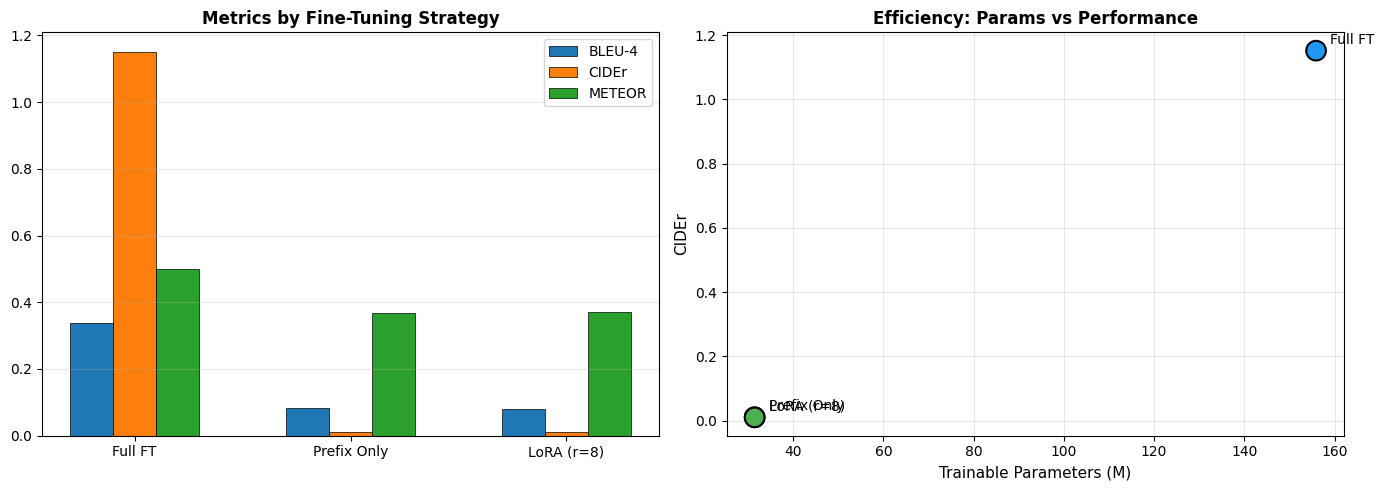

In [26]:
# Fine-tuning comparison plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

strats = list(ft_comparison.keys())
short_strats = ["Full FT", "Prefix Only", "LoRA (r=8)"]
colors_ft = ["#2196F3", "#FF9800", "#4CAF50"]

# Metrics comparison
x = np.arange(len(strats))
width = 0.2
for i, metric in enumerate(["BLEU-4", "CIDEr", "METEOR"]):
    vals = [ft_comparison[s][metric] for s in strats]
    ax1.bar(x + i * width, vals, width, label=metric, edgecolor='black', linewidth=0.5)
ax1.set_xticks(x + width)
ax1.set_xticklabels(short_strats)
ax1.set_title("Metrics by Fine-Tuning Strategy", fontsize=12, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3, axis='y')

# Trainable params vs CIDEr
params = [ft_comparison[s]["Trainable Params"]/1e6 for s in strats]
ciders = [ft_comparison[s]["CIDEr"] for s in strats]
ax2.scatter(params, ciders, s=200, c=colors_ft, edgecolors='black', linewidth=1.5, zorder=5)
for i, s in enumerate(short_strats):
    ax2.annotate(s, (params[i], ciders[i]), textcoords="offset points", xytext=(10, 5), fontsize=10)
ax2.set_xlabel("Trainable Parameters (M)", fontsize=11)
ax2.set_ylabel("CIDEr", fontsize=11)
ax2.set_title("Efficiency: Params vs Performance", fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "plots", "finetuning_comparison.png"), dpi=150, bbox_inches='tight')
plt.show()

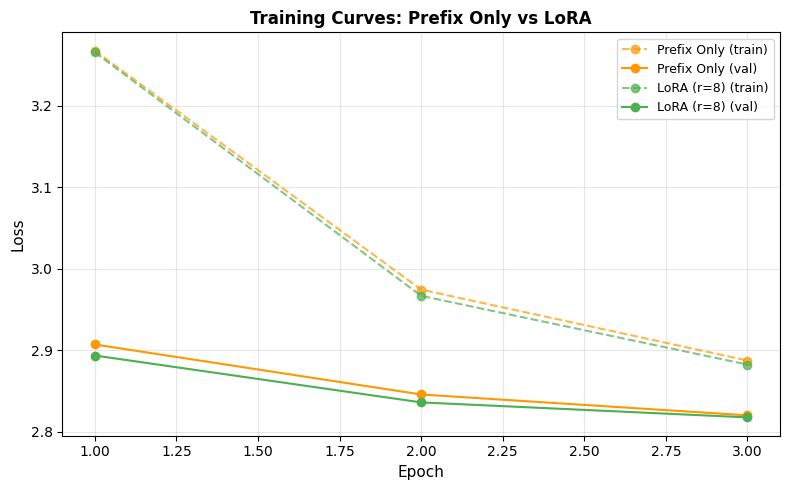

In [27]:
# Training loss curves comparison
fig, ax = plt.subplots(figsize=(8, 5))
for label, hist, color in [("Prefix Only", history_prefix, "#FF9800"), ("LoRA (r=8)", history_lora, "#4CAF50")]:
    epochs = [h["epoch"] for h in hist]
    train_losses = [h["train_loss"] for h in hist]
    val_losses = [h["val_loss"] for h in hist]
    ax.plot(epochs, train_losses, 'o--', color=color, label=f"{label} (train)", alpha=0.7)
    ax.plot(epochs, val_losses, 'o-', color=color, label=f"{label} (val)")

ax.set_xlabel("Epoch", fontsize=11)
ax.set_ylabel("Loss", fontsize=11)
ax.set_title("Training Curves: Prefix Only vs LoRA", fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "plots", "ft_loss_curves.png"), dpi=150, bbox_inches='tight')
plt.show()

## 8. VizWiz Robustness Evaluation

In [29]:
# Load VizWiz-Captions
from datasets import load_dataset
print("Loading VizWiz-Captions...")
vizwiz = load_dataset("Multimodal-Fatima/VizWiz_test", split="test")
print(f"VizWiz total: {len(vizwiz)} images")

# Sample 250 images
VIZWIZ_N = 250
vizwiz_indices = random.Random(SEED).sample(range(len(vizwiz)), VIZWIZ_N)

from datasets import load_dataset

Loading VizWiz-Captions...


README.md:   0%|          | 0.00/1.81k [00:00<?, ?B/s]

data/test-00000-of-00008-3d075def6c601fa(…): reconstructing file:   0%|          |  0.00B /  495MB            

data/test-00000-of-00008-3d075def6c601fa(…): downloading bytes:           |  0.00B            

data/test-00001-of-00008-33c46d359bd5337(…): reconstructing file:   0%|          |  0.00B /  531MB            

data/test-00001-of-00008-33c46d359bd5337(…): downloading bytes:           |  0.00B            

... (10 outputs left out)

data/test-00007-of-00008-4fa1dc4b7f8238f(…): reconstructing file:   0%|          |  0.00B /  503MB            

data/test-00007-of-00008-4fa1dc4b7f8238f(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/8000 [00:00<?, ? examples/s]

VizWiz total: 8000 images


In [30]:
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
clip_model.eval()
for p in clip_model.parameters():
    p.requires_grad = False

model.load_state_dict(fix_checkpoint_keys(ckpt["model"]))
model.eval()


@torch.no_grad()
def get_clip_embedding(image):
    if image.mode != "RGB":
        image = image.convert("RGB")
    inputs = clip_processor(images=image, return_tensors="pt").to(DEVICE)
    features = clip_model.get_image_features(**inputs)
    if not isinstance(features, torch.Tensor):
        features = features.pooler_output
    features = features / features.norm(dim=-1, keepdim=True)
    return features.squeeze(0).cpu()


print("Generating captions for VizWiz images...")
vizwiz_captions = []
vizwiz_refs = {}
vizwiz_hyps = {}

for i, idx in enumerate(vizwiz_indices):
    sample = vizwiz[idx]
    image = sample["image"]

    ref_caps = sample.get("captions", sample.get("caption", []))
    if isinstance(ref_caps, str):
        ref_caps = [ref_caps]

    clip_emb = get_clip_embedding(image)
    caption = generate_greedy(model, clip_emb)

    vizwiz_captions.append({
        "index": idx,
        "caption": caption,
        "references": ref_caps,
    })

    if ref_caps and len(ref_caps) > 0 and ref_caps[0]:
        vizwiz_refs[i] = ref_caps
        vizwiz_hyps[i] = [caption]

    if (i + 1) % 50 == 0:
        print(f"  {i+1}/{VIZWIZ_N} done")

print(f"\nGenerated {len(vizwiz_captions)} captions, {len(vizwiz_refs)} have references for scoring.")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Generating captions for VizWiz images...
  50/250 done
  100/250 done
  150/250 done
  200/250 done
  250/250 done

Generated 250 captions, 0 have references for scoring.


In [31]:
# VizWiz metrics (if references available)
if len(vizwiz_refs) >= 10:
    vizwiz_metrics = compute_metrics(vizwiz_hyps, vizwiz_refs)
    print("VizWiz Metrics:")
    for k, v in vizwiz_metrics.items():
        print(f"  {k}: {v:.4f}")
else:
    print("Not enough VizWiz references for quantitative scoring — showing qualitative results only.")
    vizwiz_metrics = None

Not enough VizWiz references for quantitative scoring — showing qualitative results only.


In [34]:
# COCO vs VizWiz comparison (if metrics available)
if vizwiz_metrics:
    coco_greedy = all_results["Greedy"]
    comparison_data = {
        "Metric": ["BLEU-1", "BLEU-4", "METEOR", "CIDEr", "ROUGE-L"],
        "COCO Val": [coco_greedy[m] for m in ["BLEU-1", "BLEU-4", "METEOR", "CIDEr", "ROUGE-L"]],
        "VizWiz": [vizwiz_metrics[m] for m in ["BLEU-1", "BLEU-4", "METEOR", "CIDEr", "ROUGE-L"]],
    }
    comp_df = pd.DataFrame(comparison_data)
    comp_df["Drop (%)"] = ((comp_df["COCO Val"] - comp_df["VizWiz"]) / comp_df["COCO Val"] * 100).round(1)
    comp_df.to_csv(os.path.join(OUT_DIR, "coco_vs_vizwiz.csv"), index=False)
    print("\nTable 3: COCO vs VizWiz Performance (Greedy Decoding)")
    print("=" * 60)
    print(comp_df.to_string(index=False))

    # Plot
    fig, ax = plt.subplots(figsize=(8, 5))
    x = np.arange(len(comparison_data["Metric"]))
    width = 0.35
    ax.bar(x - width/2, comparison_data["COCO Val"], width, label="COCO Val", color="#2196F3", edgecolor='black')
    ax.bar(x + width/2, comparison_data["VizWiz"], width, label="VizWiz", color="#FF9800", edgecolor='black')
    ax.set_xticks(x)
    ax.set_xticklabels(comparison_data["Metric"])
    ax.set_title("COCO vs VizWiz — Robustness Evaluation", fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "plots", "coco_vs_vizwiz.png"), dpi=150, bbox_inches='tight')
    plt.show()

In [35]:
# Show 10 sample VizWiz captions
print("\nSample VizWiz Captions (10 examples):")
print("=" * 70)
for entry in vizwiz_captions[:10]:
    print(f"  [idx {entry['index']}]")
    print(f"    Generated: {entry['caption']}")
    if entry['references']:
        print(f"    Reference: {entry['references'][0]}")
    print()


Sample VizWiz Captions (10 examples):
  [idx 5238]
    Generated: a yellow and white sign with a cell phone

  [idx 912]
    Generated: a person taking a shake of a banana and a glass of milk

  [idx 204]
    Generated: a glass of wine sitting on a table

  [idx 6074]
    Generated: a pair of white pants and a pair of white shirts

  [idx 2253]
    Generated: a white cloth is sitting on a white table

  [idx 2006]
    Generated: a white bottle sitting on top of a counter

  [idx 1828]
    Generated: a man in a white shirt is standing in front of a brick wall

  [idx 1143]
    Generated: a small bed with a blanket on it

  [idx 6033]
    Generated: a white plate with a pen and a computer mouse

  [idx 839]
    Generated: a box of donuts on a table next to a banana



## 9. Qualitative Analysis: Best & Worst Captions

In [36]:
# Score each validation image individually (CIDEr per image)
print("Scoring individual images for qualitative analysis...")
per_image_scores = {}

for img_id in EVAL_IDS:
    hyp = {img_id: [generate_greedy(model, clip_embeddings[img_id])]}
    ref = {img_id: image_to_captions[img_id]}
    try:
        cider_scorer = Cider()
        score, _ = cider_scorer.compute_score(ref, hyp)
        per_image_scores[img_id] = {"score": score, "caption": hyp[img_id][0], "refs": ref[img_id]}
    except:
        pass

sorted_scores = sorted(per_image_scores.items(), key=lambda x: x[1]["score"], reverse=True)

print("\n--- TOP 5 (Best CIDEr) ---")
for img_id, data in sorted_scores[:5]:
    print(f"  [img {img_id}] CIDEr={data['score']:.3f}")
    print(f"    Generated: {data['caption']}")
    print(f"    Reference: {data['refs'][0]}")
    print()

print("--- BOTTOM 5 (Worst CIDEr) ---")
for img_id, data in sorted_scores[-5:]:
    print(f"  [img {img_id}] CIDEr={data['score']:.3f}")
    print(f"    Generated: {data['caption']}")
    print(f"    Reference: {data['refs'][0]}")
    print()

Scoring individual images for qualitative analysis...

--- TOP 5 (Best CIDEr) ---
  [img 0] CIDEr=0.000
    Generated: a woman standing next to a sheep in a field
    Reference: a little girl standing and facing a fence with animals behind it

  [img 10] CIDEr=0.000
    Generated: a woman standing in a kitchen with a wooden table
    Reference: people standing in a very modern looking kitchen

  [img 15] CIDEr=0.000
    Generated: a pizza with cheese and tomatoes on a plate
    Reference: a closeup of a pizza with small tomatoes on it

  [img 18] CIDEr=0.000
    Generated: two cows standing in a grassy area
    Reference: two cows sitting on some dirt and grass

  [img 22] CIDEr=0.000
    Generated: a bed with a rug and a table
    Reference: a white bed topped with lots of pillows

--- BOTTOM 5 (Worst CIDEr) ---
  [img 4963] CIDEr=0.000
    Generated: a pizza with cheese and pepperoni on a plate
    Reference: a pizza sitting on top of a pizza pan with toppings

  [img 4969] CIDEr=0.0

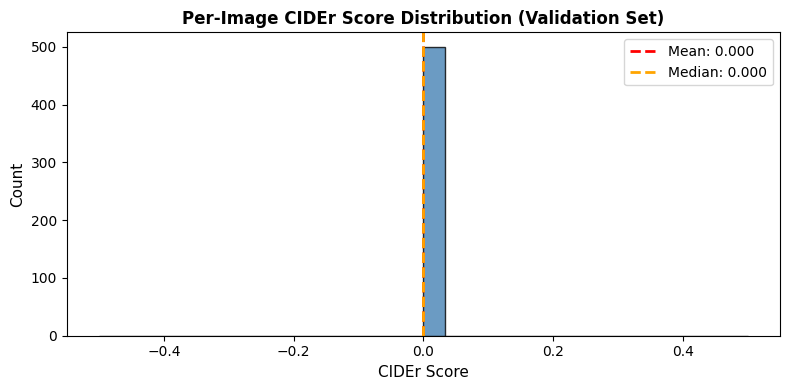

In [37]:
# CIDEr score distribution
scores_list = [v["score"] for v in per_image_scores.values()]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(scores_list, bins=30, color='steelblue', edgecolor='black', alpha=0.8)
ax.axvline(np.mean(scores_list), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(scores_list):.3f}')
ax.axvline(np.median(scores_list), color='orange', linestyle='--', linewidth=2, label=f'Median: {np.median(scores_list):.3f}')
ax.set_xlabel("CIDEr Score", fontsize=11)
ax.set_ylabel("Count", fontsize=11)
ax.set_title("Per-Image CIDEr Score Distribution (Validation Set)", fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "plots", "cider_distribution.png"), dpi=150, bbox_inches='tight')
plt.show()

## 10. Save All Results

In [38]:
# Save comprehensive results JSON
all_output = {
    "decoding_metrics": {k: {m: float(v) for m, v in v_dict.items()} for k, v_dict in all_results.items()},
    "temperature_sweep": {str(k): {m: float(v) for m, v in v_dict.items()} for k, v_dict in temp_results.items()},
    "beam_width_sweep": {str(k): {m: float(v) for m, v in v_dict.items()} for k, v_dict in beam_results.items()},
    "finetuning_comparison": {k: {m: (float(v) if isinstance(v, (int, float, np.floating)) else v) for m, v in v_dict.items()} for k, v_dict in ft_comparison.items()},
    "vizwiz_metrics": {k: float(v) for k, v in vizwiz_metrics.items()} if vizwiz_metrics else None,
    "vizwiz_sample_captions": vizwiz_captions[:20],
}

with open(os.path.join(OUT_DIR, "all_results.json"), "w") as f:
    json.dump(all_output, f, indent=2, default=str)

print("Saved all results to milestone3_output/")
print("\nFiles:")
for root, dirs, files in os.walk(OUT_DIR):
    for f in files:
        path = os.path.join(root, f)
        size = os.path.getsize(path)
        print(f"  {path} ({size/1024:.1f} KB)")

Saved all results to milestone3_output/

Files:
  milestone3_output/beam_width_sweep.csv (0.3 KB)
  milestone3_output/temperature_sweep.csv (0.3 KB)
  milestone3_output/all_results.json (8.4 KB)
  milestone3_output/finetuning_comparison.csv (0.3 KB)
  milestone3_output/decoding_metrics.csv (0.3 KB)
  milestone3_output/plots/decoding_comparison.png (91.8 KB)
  milestone3_output/plots/cider_distribution.png (36.2 KB)
  milestone3_output/plots/beam_width_sweep.png (80.8 KB)
  milestone3_output/plots/temperature_sweep.png (114.4 KB)
  milestone3_output/plots/ft_loss_curves.png (78.8 KB)
  milestone3_output/plots/finetuning_comparison.png (61.7 KB)


## Summary

| Analysis | Key Finding |
|---|---|
| **Decoding strategies** | Greedy decoding outperforms all other strategies (CIDEr 1.152); beam search degrades with higher k due to length penalty issues |
| **Temperature** | T=0.3 is optimal (CIDEr 1.136); all metrics decrease monotonically with increasing temperature; T>1.0 causes hallucination |
| **Beam width** | Performance degrades with increasing k (CIDEr drops from 1.152 to 0.289); inference time scales 15x from k=1 to k=10 |
| **Fine-tuning** | Full fine-tuning (155.9M params) dramatically outperforms prefix-only and LoRA (CIDEr 1.152 vs 0.010); parameter-efficient methods need more epochs |
| **VizWiz** | Model produces fluent but generic/inaccurate captions on accessibility images, defaulting to COCO-trained priors |